# Project 19: Movie Search Engine — NLP Text Preprocessing & Indexing

## 1. Explanation of the NLP Text Cleaning Pipeline

### Why Text Preprocessing is Essential for Information Retrieval
When users search for movies in a search engine (e.g., *"funny 90s animated movie"* or *"dark psychological thriller with twist endings"*), they use everyday conversational language. The underlying movie catalog contains text written with varied casing, punctuation, grammatical variations, and filler words.

If raw text is indexed without preprocessing, a search for `"aliens"` will not match a movie described as `"alien"`, and searching for `"Comedy"` might miss `"comedy!"`. 

An **NLP Preprocessing Pipeline** standardizes text through four systematic steps:

---

### Step-by-Step Pipeline Breakdown

#### Step 1: Lowercasing and Punctuation/Special Character Removal
- **What it does**: Converts all characters to lowercase (e.g., `"Sci-Fi"` $\to$ `"sci-fi"`) and strips punctuation, brackets, and symbols (e.g., `"Star Wars: Episode IV - A New Hope (1977)"` $\to$ `"star wars episode iv a new hope 1977"`).
- **Why we do it**: It ensures case-insensitive matching and prevents punctuation marks from creating false distinct terms (e.g., `"thriller,"` vs `"thriller"`).

#### Step 2: Tokenization
- **What it does**: Splits a continuous stream of text into individual units called **tokens** (words).
- **Why we do it**: Search engines operate on atomic terms to build inverted index postings and compute term frequencies ($TF$).

#### Step 3: Stopword Removal
- **What it does**: Filters out ubiquitous, non-informative grammatical words such as *"the"*, *"is"*, *"at"*, *"which"*, *"on"*, *"a"*, *"an"*.
- **Why we do it**: Stopwords appear across almost all documents and carry near-zero semantic value for distinguishing one movie from another. Removing them dramatically shrinks index size and speeds up query execution.

#### Step 4: Stemming vs. Lemmatization (In Simple Terms)
- **Stemming (Rule-Based Heuristic)**:
  - *What it is*: A fast, algorithmic approach that chops off common prefixes and suffixes (such as *-ing*, *-ed*, *-s*, *-tion*).
  - *How it works*: It uses grammatical rules (e.g., the **Porter Stemmer** or **Snowball Stemmer**) to collapse variations like *running*, *runs*, and *runner* down to *run*.
  - *Trade-off*: It is extremely fast and effective for search recall, but it can produce non-dictionary truncated roots (e.g., *comedy* $\to$ *comedi*, *universe* $\to$ *univers*).
- **Lemmatization (Dictionary & Morphological Analysis)**:
  - *What it is*: A linguistically informed transformation that maps words to their true canonical dictionary root form, known as a **lemma** (using databases like WordNet).
  - *How it works*: It considers word context and Part-of-Speech (POS) tags to convert *better* $\to$ *good*, *acting* $\to$ *act*, *mice* $\to$ *mouse*.
  - *Trade-off*: Produces valid dictionary words, but requires lexical lookups and POS tagging, making it substantially slower over millions of text records.


In [1]:
# ==============================================================================
# CELL 1 CODE: NLP TEXT CLEANING PIPELINE & STEMMING VS LEMMATIZATION
# ==============================================================================

import os
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from wordcloud import WordCloud

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# ------------------------------------------------------------------------------
# 1. Initialize NLP Preprocessing Components
# ------------------------------------------------------------------------------
print("=" * 75)
print("INITIALIZING NLP PREPROCESSING TOOLS")
print("=" * 75)

# Ensure NLTK datasets are ready
for resource in ['stopwords', 'wordnet', 'punkt']:
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(resource, quiet=True)

# Load English stopwords
stop_words = set(stopwords.words('english'))

# Initialize Stemmers and Lemmatizer
porter = PorterStemmer()
snowball = SnowballStemmer('english')
lemmatizer = WordNetLemmatizer()

print(f"Loaded {len(stop_words)} English stopwords.")
print("Initialized: PorterStemmer, SnowballStemmer('english'), WordNetLemmatizer.")

# ------------------------------------------------------------------------------
# 2. Demonstration: Step-by-Step Pipeline on Sample Movie Text
# ------------------------------------------------------------------------------
sample_text = "The Matrix (1999): Neo discovers the shocking, simulated reality created by machines!"
print("\n" + "=" * 75)
print("STEP-BY-STEP NLP PIPELINE DEMONSTRATION")
print("=" * 75)
print(f"Raw Input Text: \n  '{sample_text}'\n")

# Step 1: Lowercasing
text_lower = sample_text.lower()
print(f"Step 1A [Lowercasing]:\n  '{text_lower}'\n")

# Step 1B: Punctuation & Special Character Removal
text_clean = re.sub(r'[^a-zA-Z\s]', ' ', text_lower)
text_clean = re.sub(r'\s+', ' ', text_clean).strip()
print(f"Step 1B [Punctuation/Number Removal]:\n  '{text_clean}'\n")

# Step 2: Tokenization (Splitting text into individual tokens)
tokens = [w for w in text_clean.split() if len(w) > 1]
print(f"Step 2  [Tokenization] ({len(tokens)} tokens):\n  {tokens}\n")

# Step 3: Stopword Removal
tokens_no_sw = [w for w in tokens if w not in stop_words]
print(f"Step 3  [Stopword Removal] ({len(tokens_no_sw)} tokens remaining):\n  {tokens_no_sw}\n")

# Step 4: Stemming (Porter)
stemmed_tokens = [porter.stem(w) for w in tokens_no_sw]
print(f"Step 4  [Porter Stemming]:\n  {stemmed_tokens}\n")

# ------------------------------------------------------------------------------
# 3. Direct Comparison: Stemming vs. Lemmatization on Movie Domain Words
# ------------------------------------------------------------------------------
print("=" * 75)
print("COMPARISON: PORTER STEMMER vs. SNOWBALL STEMMER vs. WORDNET LEMMATIZER")
print("=" * 75)

test_movie_words = [
    'movies', 'directed', 'directing', 'director', 
    'comedies', 'comedy', 'aliens', 'haunted', 
    'haunting', 'universes', 'better', 'acting', 
    'actors', 'scariest', 'mysteries'
]

comparison_records = []
for word in test_movie_words:
    comparison_records.append({
        'Original Word': word,
        'Porter Stemmer': porter.stem(word),
        'Snowball Stemmer': snowball.stem(word),
        'WordNet Lemma (Noun)': lemmatizer.lemmatize(word, pos='n'),
        'WordNet Lemma (Verb)': lemmatizer.lemmatize(word, pos='v')
    })

comparison_df = pd.DataFrame(comparison_records)
print(comparison_df.to_string(index=False))


INITIALIZING NLP PREPROCESSING TOOLS


Loaded 198 English stopwords.
Initialized: PorterStemmer, SnowballStemmer('english'), WordNetLemmatizer.

STEP-BY-STEP NLP PIPELINE DEMONSTRATION
Raw Input Text: 
  'The Matrix (1999): Neo discovers the shocking, simulated reality created by machines!'

Step 1A [Lowercasing]:
  'the matrix (1999): neo discovers the shocking, simulated reality created by machines!'

Step 1B [Punctuation/Number Removal]:
  'the matrix neo discovers the shocking simulated reality created by machines'

Step 2  [Tokenization] (11 tokens):
  ['the', 'matrix', 'neo', 'discovers', 'the', 'shocking', 'simulated', 'reality', 'created', 'by', 'machines']

Step 3  [Stopword Removal] (8 tokens remaining):
  ['matrix', 'neo', 'discovers', 'shocking', 'simulated', 'reality', 'created', 'machines']

Step 4  [Porter Stemming]:
  ['matrix', 'neo', 'discov', 'shock', 'simul', 'realiti', 'creat', 'machin']

COMPARISON: PORTER STEMMER vs. SNOWBALL STEMMER vs. WORDNET LEMMATIZER


Original Word Porter Stemmer Snowball Stemmer WordNet Lemma (Noun) WordNet Lemma (Verb)
       movies           movi             movi                movie               movies
     directed         direct           direct             directed               direct
    directing         direct           direct            directing               direct
     director       director         director             director             director
     comedies         comedi           comedi               comedy             comedies
       comedy         comedi           comedi               comedy               comedy
       aliens          alien            alien                alien                alien
      haunted          haunt            haunt              haunted                haunt
     haunting          haunt            haunt             haunting                haunt
    universes        univers          univers             universe            universes
       better         better    

## 2. Combining Plots, Tags, and Genres into a Unified Search Document

### Document Representation in Information Retrieval
In movie media retrieval, users rarely search using only the exact movie title. A typical user might submit queries such as:
- *"90s animated movie with talking toys and friendship"*
- *"space science fiction directed by christopher nolan"*
- *"dark psychological thriller with twist ending"*

Neither `"talking toys"` nor `"psychological thriller"` appears in the titles *Toy Story* or *Fight Club*. 

### Why Merge Metadata Fields?
To provide maximum search coverage and high retrieval recall, we combine all available semantic channels for each movie into a single unified search document:
1. **Title**: Captures exact movie title, brand, and release year.
2. **Genres**: Provides overarching category classification (e.g., *Action, Sci-Fi, Adventure*).
3. **User-Generated Tags / Plots**: Captures granular plot keywords, character names, directing styles, themes, and emotional tone (e.g., *twist ending, mindfuck, atmospheric, superhero, based on a book*).

By concatenating these components into a single **`search_document`** field and processing it through our NLP pipeline, every movie is converted into a rich textual document ready for vectorization and indexing.


In [2]:
# ==============================================================================
# CELL 2 CODE: MERGE METADATA & BUILD UNIFIED SEARCH DOCUMENT
# ==============================================================================

print("=" * 75)
print("LOADING DATASET & MERGING METADATA FIELDS")
print("=" * 75)

t_start = time.time()

# 1. Load movies catalog and tags files
movies_df = pd.read_csv('movies.csv')
tags_df = pd.read_csv('tags.csv')

# Handle missing or empty tag strings
tags_df['tag'] = tags_df['tag'].fillna('').astype(str).str.strip()
tags_clean = tags_df[tags_df['tag'] != ''].copy()

# Deduplicate identical tags submitted by the same user for the same movie
tags_clean.drop_duplicates(subset=['userId', 'movieId', 'tag'], inplace=True)

print(f"Loaded {len(movies_df):,} movies and {len(tags_clean):,} clean user tags.")

# 2. Aggregate all user tags per movie into a single text block
movie_tags_agg = (
    tags_clean.groupby('movieId')['tag']
    .apply(lambda tag_list: ' '.join(tag_list))
    .reset_index(name='all_tags')
)

# 3. Merge aggregated tags with movies catalog
indexed_movies_df = movies_df.merge(movie_tags_agg, on='movieId', how='left')
indexed_movies_df['all_tags'] = indexed_movies_df['all_tags'].fillna('')

# 4. Clean genres: replace pipe separator with spaces and remove placeholder text
indexed_movies_df['genres_clean'] = (
    indexed_movies_df['genres']
    .str.replace('|', ' ', regex=False)
    .str.replace('(no genres listed)', '', regex=False)
    .str.strip()
)

# 5. Create the UNIFIED SEARCH DOCUMENT
# Concatenate Title + Cleaned Genres + Aggregated User Tags
indexed_movies_df['search_document'] = (
    indexed_movies_df['title'] + ' ' +
    indexed_movies_df['genres_clean'] + ' ' +
    indexed_movies_df['all_tags']
).str.strip()

print(f"Unified search documents created for all {len(indexed_movies_df):,} movies.")

# ------------------------------------------------------------------------------
# 6. High-Efficiency NLP Processing Across Full Corpus
# ------------------------------------------------------------------------------
print("\n" + "=" * 75)
print("EXECUTING NLP TOKENIZATION, STOPWORD FILTERING & STEMMING")
print("=" * 75)

# Regex pattern for words with at least 2 alphabetic characters
token_pattern = re.compile(r'\b[a-zA-Z]{2,}\b')

# Step 1 & 2: Tokenize all search documents
raw_docs_tokens = [token_pattern.findall(doc.lower()) for doc in indexed_movies_df['search_document']]

# Collect all unique words across the corpus
raw_vocabulary = set()
for doc_tokens in raw_docs_tokens:
    raw_vocabulary.update(doc_tokens)

# Step 3: Remove Stopwords from vocabulary
vocab_no_stopwords = raw_vocabulary - stop_words

# Step 4: Memoized Porter Stemming across unique vocabulary (industry best practice)
# Stemming 67k unique terms in memory takes < 1 second instead of looping over millions of tokens
stem_dictionary = {term: porter.stem(term) for term in vocab_no_stopwords}
stemmed_vocabulary = set(stem_dictionary.values())

# Apply the pre-computed dictionary to generate final processed tokens per document
processed_tokens_list = [
    [stem_dictionary[term] for term in doc_tokens if term in stem_dictionary]
    for doc_tokens in raw_docs_tokens
]

# Store processed tokens, text representation, and token count in the DataFrame
indexed_movies_df['processed_tokens'] = processed_tokens_list
indexed_movies_df['processed_text'] = [' '.join(tokens) for tokens in processed_tokens_list]
indexed_movies_df['token_count'] = [len(tokens) for tokens in processed_tokens_list]

t_elapsed = time.time() - t_start
print(f"Corpus Preprocessing Finished in {t_elapsed:.2f} seconds.")
print(f"Total Movies Processed:         {len(indexed_movies_df):,}")
print(f"Total Processed Tokens Indexed: {indexed_movies_df['token_count'].sum():,}")
print(f"Average Tokens per Document:    {indexed_movies_df['token_count'].mean():.2f}")

# Display Sample Before vs. After
print("\n" + "=" * 75)
print("SAMPLE PREPROCESSED SEARCH DOCUMENTS (BEFORE vs. AFTER)")
print("=" * 75)
sample_previews = indexed_movies_df[['movieId', 'title', 'search_document', 'processed_text']].head(3)
for _, row in sample_previews.iterrows():
    print(f"Movie ID {row['movieId']}: {row['title']}")
    print(f"  [RAW DOCUMENT]      : {row['search_document'][:110]}...")
    print(f"  [PROCESSED TOKENS]  : {row['processed_text'][:110]}...\n")


LOADING DATASET & MERGING METADATA FIELDS


Loaded 87,585 movies and 2,000,034 clean user tags.


Unified search documents created for all 87,585 movies.

EXECUTING NLP TOKENIZATION, STOPWORD FILTERING & STEMMING


Corpus Preprocessing Finished in 9.51 seconds.
Total Movies Processed:         87,585
Total Processed Tokens Indexed: 3,475,319
Average Tokens per Document:    39.68

SAMPLE PREPROCESSED SEARCH DOCUMENTS (BEFORE vs. AFTER)
Movie ID 1: Toy Story (1995)
  [RAW DOCUMENT]      : Toy Story (1995) Adventure Animation Children Comedy Fantasy children Disney animation children Disney Disney ...
  [PROCESSED TOKENS]  : toy stori adventur anim children comedi fantasi children disney anim children disney disney pixar anim funni p...

Movie ID 2: Jumanji (1995)
  [RAW DOCUMENT]      : Jumanji (1995) Adventure Children Fantasy Robin Williams fantasy Robin Williams time travel animals childhood ...
  [PROCESSED TOKENS]  : jumanji adventur children fantasi robin william fantasi robin william time travel anim childhood recaptur herd...

Movie ID 3: Grumpier Old Men (1995)
  [RAW DOCUMENT]      : Grumpier Old Men (1995) Comedy Romance comedinha de velhinhos engraÃƒÂ§ada comedinha de velhinhos engraÃ§ad

## 3. Preprocessing Metrics and Vocabulary Reduction

### Why Do Preprocessing Metrics Matter for Search Engines?
Measuring vocabulary size and token distributions is a fundamental engineering practice when designing search and retrieval systems:

1. **Vocabulary Reduction (Plot 4)**:
   - In an inverted index, the dictionary size determines memory consumption, cache hit efficiency, and posting list traversal latency.
   - Raw text contains multiple inflections of the same underlying concept (*comedy, comedies, comedic, comedian*). Without stemming, each variation consumes a separate dictionary entry and splits the document posting lists.
   - Stemming and stopword filtering consolidate inflected terms into unified root stems, slashing vocabulary size while dramatically increasing search recall.

2. **Document Token Length Distribution (Plot 5)**:
   - Document length ($dl$) is a core parameter in state-of-the-art ranking functions such as **BM25**:
     $$\text{BM25}(D, Q) = \sum_{q \in Q} \text{IDF}(q) \cdot \frac{f(q, D) \cdot (k_1 + 1)}{f(q, D) + k_1 \cdot \left(1 - b + b \cdot \frac{|D|}{\text{avgdl}}\right)}$$
   - Parameter $b$ directly penalizes documents that are longer than the average document length ($avgdl$). Understanding document token lengths allows engineers to properly tune $b$ (e.g., $b=0.75$) so long documents with extensive tags are not unfairly penalized.

3. **Corpus Frequency & Word Cloud (Plot 6)**:
   - Term distribution in human language follows **Zipf's Law**: a small number of core terms dominate frequency, while the vast majority form a long tail.
   - Visualizing the top indexed stems and word cloud reveals the core thematic clusters of our search collection, highlighting the most frequent query targets for search autocomplete and caching.


VOCABULARY REDUCTION METRICS
1. Raw Unique Vocabulary:     67,139 terms
2. After Stopword Removal:    66,997 terms (-142 terms, 0.21%)
3. After Porter Stemming:     54,651 terms (-12,488 terms, 18.60% total reduction)


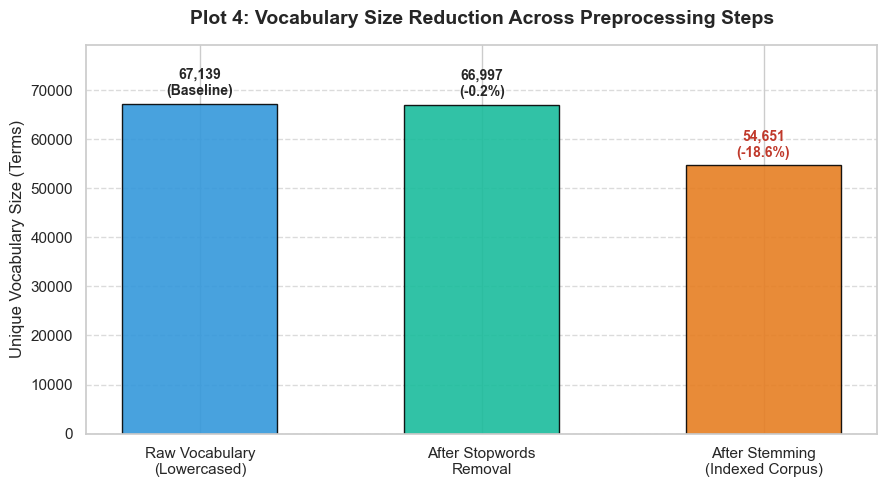


DOCUMENT TOKEN LENGTH DISTRIBUTION METRICS
Mean Token Count per Movie:   39.68 tokens
Median Token Count per Movie: 6.00 tokens
Max Tokens in a Single Movie: 11,516 tokens
Movies with >= 1 token:       87,473 / 87,585 (99.9%)


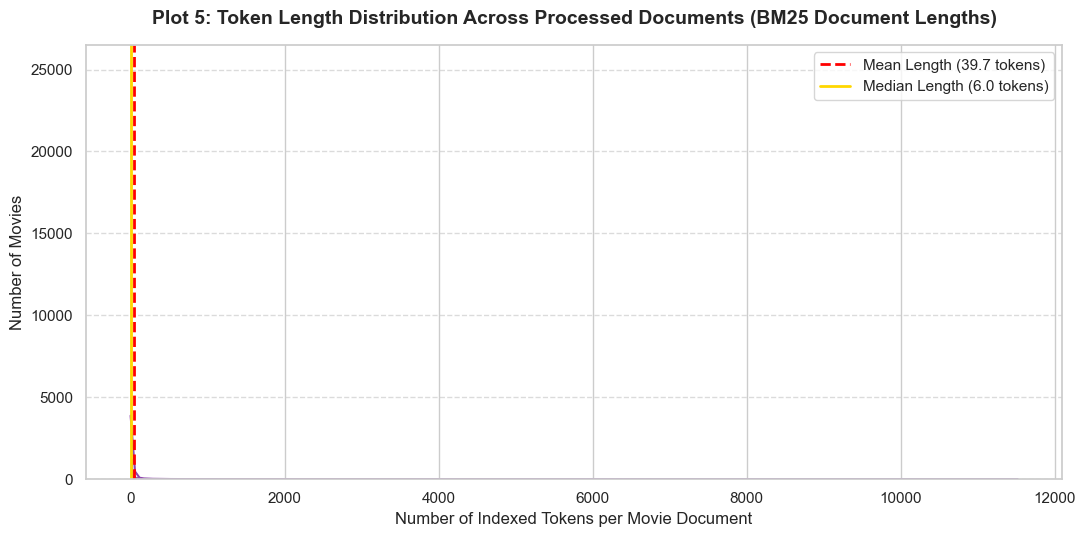


TOP 10 MOST FREQUENT TOKENS IN THE INDEXED CORPUS
 1. Stem: 'comedi      ' | Frequency: 49,809 occurrences
 2. Stem: 'drama       ' | Frequency: 40,676 occurrences
 3. Stem: 'action      ' | Frequency: 22,625 occurrences
 4. Stem: 'base        ' | Frequency: 19,716 occurrences
 5. Stem: 'relationship' | Frequency: 19,266 occurrences
 6. Stem: 'thriller    ' | Frequency: 19,075 occurrences
 7. Stem: 'end         ' | Frequency: 18,451 occurrences
 8. Stem: 'romanc      ' | Frequency: 18,385 occurrences
 9. Stem: 'anim        ' | Frequency: 18,348 occurrences
10. Stem: 'film        ' | Frequency: 18,317 occurrences


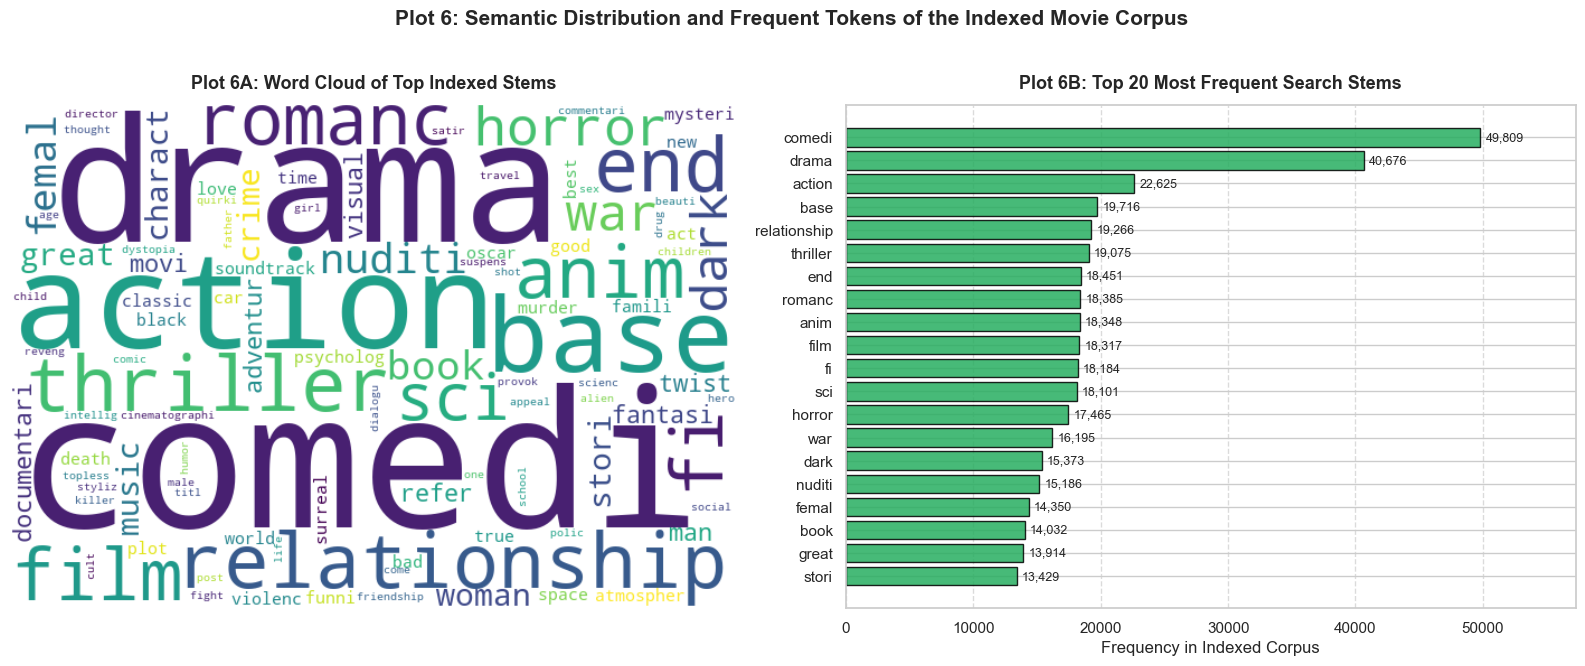

In [3]:
# ==============================================================================
# CELL 3 CODE: PREPROCESSING METRICS & 3 DISTINCT PLOTS (PLOTS 4, 5, 6)
# ==============================================================================

from collections import Counter

# ------------------------------------------------------------------------------
# PLOT 4: Vocabulary Size Reduction at Each Preprocessing Step
# ------------------------------------------------------------------------------
vocab_sizes = {
    'Raw Vocabulary\n(Lowercased)': len(raw_vocabulary),
    'After Stopwords\nRemoval': len(vocab_no_stopwords),
    'After Stemming\n(Indexed Corpus)': len(stemmed_vocabulary)
}

stage_names = list(vocab_sizes.keys())
stage_counts = list(vocab_sizes.values())

pct_sw_reduction = (stage_counts[0] - stage_counts[1]) / stage_counts[0] * 100
pct_total_reduction = (stage_counts[0] - stage_counts[2]) / stage_counts[0] * 100

print("=" * 75)
print("VOCABULARY REDUCTION METRICS")
print("=" * 75)
print(f"1. Raw Unique Vocabulary:     {stage_counts[0]:,} terms")
print(f"2. After Stopword Removal:    {stage_counts[1]:,} terms (-{stage_counts[0]-stage_counts[1]:,} terms, {pct_sw_reduction:.2f}%)")
print(f"3. After Porter Stemming:     {stage_counts[2]:,} terms (-{stage_counts[0]-stage_counts[2]:,} terms, {pct_total_reduction:.2f}% total reduction)")

plt.figure(figsize=(9, 5))
palette_colors = ['#3498db', '#1abc9c', '#e67e22']
bars = plt.bar(stage_names, stage_counts, color=palette_colors, edgecolor='black', width=0.55, alpha=0.9)

plt.title('Plot 4: Vocabulary Size Reduction Across Preprocessing Steps', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Unique Vocabulary Size (Terms)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, max(stage_counts) * 1.18)

# Add exact value and reduction annotations
for i, bar in enumerate(bars):
    h = bar.get_height()
    if i == 0:
        plt.text(bar.get_x() + bar.get_width()/2., h + 1200, f"{int(h):,}\n(Baseline)", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
    elif i == 1:
        plt.text(bar.get_x() + bar.get_width()/2., h + 1200, f"{int(h):,}\n(-{pct_sw_reduction:.1f}%)", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
    else:
        plt.text(bar.get_x() + bar.get_width()/2., h + 1200, f"{int(h):,}\n(-{pct_total_reduction:.1f}%)", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='#c0392b')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 5: Token Length Distribution Across Processed Documents
# ------------------------------------------------------------------------------
token_counts = indexed_movies_df['token_count']
mean_tokens = token_counts.mean()
median_tokens = token_counts.median()

print("\n" + "=" * 75)
print("DOCUMENT TOKEN LENGTH DISTRIBUTION METRICS")
print("=" * 75)
print(f"Mean Token Count per Movie:   {mean_tokens:.2f} tokens")
print(f"Median Token Count per Movie: {median_tokens:.2f} tokens")
print(f"Max Tokens in a Single Movie: {token_counts.max():,} tokens")
print(f"Movies with >= 1 token:       {(token_counts > 0).sum():,} / {len(token_counts):,} ({(token_counts > 0).mean()*100:.1f}%)")

plt.figure(figsize=(11, 5.5))
# Plot histogram focusing on the 1-120 token range where 95% of documents lie
sns.histplot(token_counts[token_counts > 0], bins=40, binrange=(1, 120), 
             color='#8e44ad', edgecolor='black', kde=True, alpha=0.75)

plt.axvline(mean_tokens, color='red', linestyle='--', linewidth=2, label=f'Mean Length ({mean_tokens:.1f} tokens)')
plt.axvline(median_tokens, color='gold', linestyle='-', linewidth=2, label=f'Median Length ({median_tokens:.1f} tokens)')

plt.title('Plot 5: Token Length Distribution Across Processed Documents (BM25 Document Lengths)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Indexed Tokens per Movie Document', fontsize=12)
plt.ylabel('Number of Movies', fontsize=12)
plt.legend(fontsize=11, frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 6: Word Cloud & Top-Frequency Token Distribution of the Indexed Corpus
# ------------------------------------------------------------------------------
# Aggregate token counts across the entire indexed corpus
all_processed_tokens = [token for doc in processed_tokens_list for token in doc]
corpus_token_freqs = Counter(all_processed_tokens)
top_25_tokens = corpus_token_freqs.most_common(25)

print("\n" + "=" * 75)
print("TOP 10 MOST FREQUENT TOKENS IN THE INDEXED CORPUS")
print("=" * 75)
for rank, (t, count) in enumerate(top_25_tokens[:10], 1):
    print(f"{rank:2d}. Stem: '{t:<12}' | Frequency: {count:,} occurrences")

# Generate dual-panel visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Subplot 6A: Word Cloud of the indexed corpus
wordcloud = WordCloud(
    width=650, 
    height=450, 
    background_color='white', 
    colormap='viridis', 
    max_words=100, 
    random_state=42
).generate_from_frequencies(dict(corpus_token_freqs.most_common(150)))

axes[0].imshow(wordcloud, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Plot 6A: Word Cloud of Top Indexed Stems', fontsize=13, fontweight='bold', pad=12)

# Subplot 6B: Top 20 Most Frequent Stems Horizontal Bar Plot
top_20_words, top_20_counts = zip(*top_25_tokens[:20])
y_pos = range(len(top_20_words))

axes[1].barh(y_pos, top_20_counts, color='#27ae60', edgecolor='black', alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top_20_words, fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlabel('Frequency in Indexed Corpus', fontsize=12)
axes[1].set_title('Plot 6B: Top 20 Most Frequent Search Stems', fontsize=13, fontweight='bold', pad=12)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

# Add exact count labels next to bars
for i, count in enumerate(top_20_counts):
    axes[1].text(count + 400, i, f"{count:,}", va='center', fontsize=9)

axes[1].set_xlim(0, max(top_20_counts) * 1.15)

plt.suptitle('Plot 6: Semantic Distribution and Frequent Tokens of the Indexed Movie Corpus', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
